# 1 · Predict and evaluate day-ahead prices

Two simple XGBoost regressors, with an identical chronological **80% train / 20% test split**:

| Model | Inputs | Target |
|---|---|---|
| Weather | Archived Open-Meteo weather forecasts + calendar | DA price, EUR/MWh |
| Fundamentals | Total generation forecast + residual-load forecast + calendar | DA price, EUR/MWh |

Residual-load forecast = load forecast − wind forecast − solar forecast. Historical DA prices are training **labels**, as in the original model, not contemporaneous predictors. Both models use identical eligible timestamps and fixed parameters. No test-based tuning or early stopping.

A third, deliberately simple **training-only calendar-mean benchmark** becomes the hypothetical counterparty quote in Part 2. The benchmark is fixed after training and never updates with test labels.

This notebook is standalone: no `.py` files are needed. Run this notebook first; then run `hypothetical_contract.ipynb`. Run All defaults to **real-data mode**, which needs your ENTSO-E token. Set `DEMO = True` for a fully synthetic demonstration.


## Dependencies

If needed, uncomment and run the installation cell. Restart the kernel after installing, then run all cells from the top.

In [ ]:
# %pip install numpy pandas requests entsoe-py xgboost scikit-learn plotly

## Embedded implementation

All functions are included here; no local `.py` imports are needed.

In [47]:
import argparse
from dataclasses import dataclass, asdict
import hashlib
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
WEATHER_COLS = ['temperature_2m', 'wind_speed_10m', 'wind_speed_100m',
                'cloud_cover', 'direct_radiation', 'diffuse_radiation']
CALENDAR_COLS = ['hour', 'minute', 'dayofweek', 'month']
FEATURES = {'weather': WEATHER_COLS + CALENDAR_COLS,
            'fundamentals': ['generation_forecast_mw', 'residual_load_forecast_mw'] + CALENDAR_COLS}
PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.05,
              objective='reg:squarederror', random_state=42, n_jobs=2)

In [48]:
@dataclass(frozen=True)
class PredictionConfig:
    zone: str = 'DK_2'
    timezone: str = 'Europe/Copenhagen'
    start_date: str = '2025-01-01'
    end_date: str = '2026-10-25'  # exclusive
    latitude: float = 55.6759
    longitude: float = 12.5655
    weather_model: str = 'dmi_seamless'
    train_fraction: float = 0.8
    high_quantile: float = 0.9
    fixed_high_price: float = 200.0
    decision_hour_local: int = 10  # assumed previous-day decision time, not exchange specification

In [49]:
def validate_config(cfg):
    if not 0 < cfg.train_fraction < 1 or not 0 < cfg.high_quantile < 1:
        raise ValueError('Fractions must be strictly between zero and one.')
    if not 0 <= cfg.decision_hour_local <= 23:
        raise ValueError('decision_hour_local must be 0..23.')
    if not -90 <= cfg.latitude <= 90 or not -180 <= cfg.longitude <= 180:
        raise ValueError('Invalid coordinates.')
    start = pd.Timestamp(cfg.start_date, tz=cfg.timezone)
    end = pd.Timestamp(cfg.end_date, tz=cfg.timezone)
    if end <= start:
        raise ValueError('end_date must be after start_date.')
    return start, end

In [50]:
def as_utc(obj):
    obj = obj.copy()
    if not isinstance(obj.index, pd.DatetimeIndex) or obj.index.tz is None:
        raise ValueError('Expected a timezone-aware DatetimeIndex.')
    obj.index = obj.index.tz_convert('UTC')
    obj = obj.sort_index()
    if obj.index.has_duplicates:
        raise ValueError('Duplicate timestamps: inspect source revisions before modelling.')
    return obj.apply(pd.to_numeric, errors='coerce') if isinstance(obj, pd.DataFrame) else pd.to_numeric(obj, errors='coerce')

In [51]:
def to_quarter_hours(obj, target_grid):
    obj = as_utc(obj)
    differences = obj.index.to_series().diff().dropna()
    if differences.empty:
        raise ValueError('Not enough observations to infer source interval.')
    interval = differences.mode().iloc[0]
    if interval not in [pd.Timedelta('15min'), pd.Timedelta('30min'), pd.Timedelta('1h')]:
        raise ValueError(f'Unsupported source interval: {interval}')
    # Regularise first so an absent source record cannot inherit an earlier value.
    regular = pd.date_range(obj.index.min(), obj.index.max(), freq=interval)
    if not obj.index.isin(regular).all():
        raise ValueError('Mixed/off-grid intervals; inspect and normalise the source first.')
    obj = obj.reindex(regular)
    return obj.reindex(target_grid, method='ffill',
                       tolerance=interval-pd.Timedelta('1ns'))

In [52]:
def select_series(obj, preferred, name):
    if isinstance(obj, pd.Series):
        return obj.rename(name)
    if preferred in obj.columns:
        return obj[preferred].rename(name)
    if obj.shape[1] == 1:
        return obj.iloc[:, 0].rename(name)
    raise ValueError(f'Cannot identify {name}; available columns: {list(obj.columns)}')

In [72]:
def fetch_data(cfg, token=None):
    """Fetch retrospective data. These endpoints do NOT certify pre-auction vintages."""
    import requests
    from entsoe import EntsoePandasClient
    start, end = validate_config(cfg)
    token = token or os.environ.get('ENTSOE_API_TOKEN', '').strip()
    key_file = Path.cwd().parent.parent / 'entsoe-api.txt'
    if not token and key_file.exists():
        token = key_file.read_text(encoding='utf-8').strip()
    if not token:
        raise RuntimeError('Set ENTSO-E token using environment variable ENTSOE_API_TOKEN or ../entsoe-api.txt.')
    client = EntsoePandasClient(api_key=token)
    start_utc, end_utc = start.tz_convert('UTC'), end.tz_convert('UTC')
    grid = pd.date_range(start_utc, end_utc, freq='15min', inclusive='left')
    response = requests.get('https://historical-forecast-api.open-meteo.com/v1/forecast',
        params={'latitude': cfg.latitude, 'longitude': cfg.longitude,
                'start_date': start_utc.date().isoformat(),
                'end_date': (end_utc-pd.Timedelta('1ns')).date().isoformat(),
                'hourly': ','.join(WEATHER_COLS), 'models': cfg.weather_model,
                'wind_speed_unit': 'ms', 'timezone': 'UTC'}, timeout=120)
    response.raise_for_status()
    payload = response.json()
    if 'hourly' not in payload:
        raise ValueError('No hourly weather data returned; check model and date coverage.')
    weather = pd.DataFrame(payload['hourly'])
    weather.index = pd.to_datetime(weather.pop('time'), utc=True)
    weather = to_quarter_hours(weather[WEATHER_COLS], grid)
    prices = as_utc(client.query_day_ahead_prices(cfg.zone, start=start, end=end))
    if not isinstance(prices, pd.Series):
        raise ValueError('Expected one DA price series.')
    differences = prices.index.to_series().diff().dropna()
    if differences.empty or differences.mode().iloc[0] != pd.Timedelta('15min'):
        raise ValueError('15-minute target prices are required; prices are never forward-filled.')
    generation = select_series(client.query_generation_forecast(cfg.zone, start=start, end=end),
                               'Actual Aggregated', 'generation_forecast_mw')
    load = select_series(client.query_load_forecast(cfg.zone, start=start, end=end),
                         'Forecasted Load', 'load_forecast_mw')
    renewable = client.query_wind_and_solar_forecast(cfg.zone, start=start, end=end, psr_type=None)
    required = ['Solar', 'Wind Offshore', 'Wind Onshore']
    missing = set(required)-set(renewable.columns)
    if missing:
        raise ValueError(f'Missing forecast components: {missing}. Verify absence before assuming zero.')
    fundamental = pd.concat([to_quarter_hours(generation, grid), to_quarter_hours(load, grid),
                              to_quarter_hours(renewable[required], grid)], axis=1)
    fundamental['wind_solar_forecast_mw'] = fundamental[required].sum(axis=1, min_count=3)
    fundamental['residual_load_forecast_mw'] = (fundamental['load_forecast_mw']
                                               - fundamental['wind_solar_forecast_mw'])
    return pd.concat([prices.reindex(grid).rename('actual_da'), weather, fundamental], axis=1)

In [54]:
def demo_data(cfg, seed=42):
    """Entirely synthetic data to exercise the pipeline; not observed market history."""
    start, end = validate_config(cfg)
    index = pd.date_range(start.tz_convert('UTC'), end.tz_convert('UTC'), freq='15min', inclusive='left')
    rng = np.random.default_rng(seed)
    h = index.tz_convert(cfg.timezone).hour.to_numpy()
    days = np.arange(len(index))/96
    wind = np.maximum(0, 6 + 3*np.sin(days/3) + rng.normal(0, 0.5, len(index)))
    solar = np.maximum(0, np.sin((h-6)*np.pi/12))
    load = 1800+400*np.cos((h-18)*np.pi/12)+rng.normal(0,35,len(index))
    residual = load-150*wind-500*solar
    df = pd.DataFrame(index=index)
    df['temperature_2m'] = 15+5*np.sin(days/20)+3*solar
    df['wind_speed_10m'], df['wind_speed_100m'] = wind*.7, wind
    df['cloud_cover'] = rng.uniform(0,100,len(index))
    df['direct_radiation'], df['diffuse_radiation'] = solar*600, solar*100
    df['load_forecast_mw'] = load
    df['generation_forecast_mw'] = 1900+100*wind+200*solar
    df['residual_load_forecast_mw'] = residual
    df['actual_da'] = (25+.05*residual + .00008*np.maximum(residual-1000,0)**2
                       + rng.normal(0,15,len(index)))
    return df

In [55]:
def calendar_features(index, timezone):
    local = index.tz_convert(timezone)
    return pd.DataFrame({'hour':local.hour, 'minute':local.minute,
                         'dayofweek':local.dayofweek, 'month':local.month}, index=index)

In [56]:
def decision_times(index, cfg):
    # Subtract calendar dates, not 24 elapsed hours, so DST preserves local decision time.
    day = index.tz_convert(cfg.timezone).tz_localize(None).normalize()-pd.Timedelta(days=1)
    return (day+pd.Timedelta(hours=cfg.decision_hour_local)).tz_localize(
        cfg.timezone, ambiguous='raise', nonexistent='raise').tz_convert('UTC')

In [57]:
def benchmark_quotes(train, test):
    """Fixed train-only mean by weekday/hour/quarter-hour; fallback to hour then global mean."""
    keys = ['dayofweek', 'hour', 'minute']
    grouped = train.groupby(keys)['actual_da'].mean()
    lookup = pd.MultiIndex.from_frame(test[keys])
    quote = pd.Series(grouped.reindex(lookup).to_numpy(), index=test.index)
    return quote.fillna(test['hour'].map(train.groupby('hour')['actual_da'].mean())).fillna(train['actual_da'].mean())

In [58]:
def evaluate(predictions, threshold, fixed_threshold=200.):
    rows = []
    masks = {'overall': pd.Series(True,index=predictions.index),
             'high_train_quantile':predictions.actual_da >= threshold,
             'below_train_p90':predictions.actual_da < threshold,
             'high_fixed':predictions.actual_da >= fixed_threshold}
    for model in ['weather', 'fundamentals', 'benchmark']:
        col = 'quote_mid' if model=='benchmark' else f'pred_{model}'
        for subset, mask in masks.items():
            p = predictions.loc[mask]
            error = p[col]-p.actual_da
            rows.append(dict(model=model,subset=subset,n=len(p),
                mae=mean_absolute_error(p.actual_da,p[col]) if len(p) else np.nan,
                rmse=np.sqrt(mean_squared_error(p.actual_da,p[col])) if len(p) else np.nan,
                bias=error.mean(), underprediction_pct=100*(error<0).mean() if len(p) else np.nan,
                r2=r2_score(p.actual_da,p[col]) if len(p)>1 and p.actual_da.nunique()>1 else np.nan))
    return pd.DataFrame(rows)

In [59]:
def fit_evaluate(raw, cfg, synthetic=False):
    """Both models fit the first 80% only. No test-based early stopping or tuning."""
    from xgboost import XGBRegressor
    start, end = validate_config(cfg)
    raw = as_utc(raw)
    grid = pd.date_range(start.tz_convert('UTC'),end.tz_convert('UTC'),freq='15min',inclusive='left')
    if not raw.index.isin(grid).all():
        raise ValueError('Input contains off-grid/out-of-period observations.')
    raw = raw.reindex(grid)
    needed = list(dict.fromkeys(['actual_da']+WEATHER_COLS+FEATURES['fundamentals'][:-4]))
    missing = set(needed)-set(raw.columns)
    if missing:
        raise ValueError(f'Missing input columns: {missing}')
    raw = raw[needed].replace([np.inf,-np.inf],np.nan)
    missing_report = raw.isna().sum().rename('missing_intervals').to_frame()
    data = raw.join(calendar_features(raw.index,cfg.timezone)).dropna()
    cut = int(len(data)*cfg.train_fraction)
    if cut<100 or len(data)-cut<20:
        raise ValueError('Need at least 100 training rows and 20 test rows.')
    train, test = data.iloc[:cut].copy(),data.iloc[cut:].copy()
    assert train.index.max()<test.index.min()
    result = pd.DataFrame({'actual_da':test.actual_da}, index=test.index)
    models = {}
    for name, features in FEATURES.items():
        model = XGBRegressor(**PARAMS)
        model.fit(train[features],train.actual_da)
        result[f'pred_{name}'] = model.predict(test[features])
        models[name] = model
    result['quote_mid'] = benchmark_quotes(train,test)
    result['decision_time_utc'] = decision_times(test.index,cfg)
    result['duration_hours'] = .25
    # Conservative assumption: all training labels available after last training delivery.
    trained_through = train.index[-1]+pd.Timedelta('15min')
    result['eligible_for_contract'] = result.decision_time_utc > trained_through
    threshold = float(train.actual_da.quantile(cfg.high_quantile))
    result['high_price'] = result.actual_da >= threshold
    result.index.name = 'delivery_start_utc'
    metadata = dict(schema_version=1, synthetic=bool(synthetic),
        forecast_vintages_verified=False,
        purpose='Hypothetical retrospective research; not demonstrated executable market returns',
        config=asdict(cfg), model_params=PARAMS, features=FEATURES,
        quote_method='Frozen training mean by weekday/hour/quarter-hour, fallback hour/global mean',
        train_start=str(train.index[0]), train_end=str(train.index[-1]),
        training_labels_available_assumed_utc=str(trained_through),
        test_start=str(test.index[0]),test_end=str(test.index[-1]),
        n_train=len(train),n_test=len(test),n_expected=len(raw),n_dropped=len(raw)-len(data),
        high_threshold=threshold,
        contract_eligible_intervals=int(result.eligible_for_contract.sum()))
    return dict(predictions=result,metrics=evaluate(result,threshold,cfg.fixed_high_price),
                metadata=metadata, models=models, missing_report=missing_report)

In [60]:
def explain_metrics(metrics):
    messages = []
    for model in ['weather','fundamentals']:
        table = metrics[metrics.model==model].set_index('subset')
        overall,high = table.loc['overall'],table.loc['high_train_quantile']
        messages.append(f"{model}: overall MAE EUR {overall.mae:.2f}/MWh.")
        if high.n:
            ratio = high.mae/overall.mae if overall.mae else np.nan
            messages.append(f"  High-price MAE EUR {high.mae:.2f}/MWh ({ratio:.2f}x overall), "
                            f"n={int(high.n)}, bias EUR {high.bias:.2f}/MWh.")
        else:
            messages.append('  No high-price test observations; high-price MAE unavailable.')
    messages.append('Negative bias means underprediction. MAE is not percentage error or profit.')
    return '\n'.join(messages)

In [61]:
def export_result(result, output):
    output = Path(output); output.mkdir(parents=True,exist_ok=True)
    path = output/'test_predictions.csv'
    result['predictions'].to_csv(path)
    meta = dict(result['metadata'])
    meta['predictions_sha256'] = hashlib.sha256(path.read_bytes()).hexdigest()
    (output/'metadata.json').write_text(json.dumps(meta,indent=2),encoding='utf-8')
    result['metrics'].to_csv(output/'prediction_metrics.csv',index=False)
    result['missing_report'].to_csv(output/'data_quality.csv')
    for name,model in result['models'].items():
        model.save_model(output/f'xgboost_{name}.json')
    return output

In [62]:
def prediction_figure(predictions):
    import plotly.express as px
    return px.line(predictions,x=predictions.index,
        y=['actual_da','pred_weather','pred_fundamentals','quote_mid'],
        title='Held-out DA predictions and hypothetical quote benchmark',
        labels={'value':'EUR/MWh','delivery_start_utc':'Delivery (UTC)'},template='plotly_white')

In [63]:
def feature_importance_table(result):
    """Training-tree average gain, normalised within each model; no holdout fitting."""
    rows = []
    for name, model in result['models'].items():
        scores = model.get_booster().get_score(importance_type='gain')
        features = result['metadata']['features'][name]
        gains = np.array([scores.get(f, scores.get(f'f{i}', 0.0)) for i, f in enumerate(features)])
        shares = 100*gains/gains.sum() if gains.sum() else np.zeros(len(features))
        rows.extend(dict(model=name, feature=f, average_gain=float(g), importance_pct=float(s))
                    for f,g,s in zip(features,gains,shares))
    return pd.DataFrame(rows)

In [64]:
def feature_importance_figure(result):
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    table = feature_importance_table(result)
    fig = make_subplots(rows=1, cols=2, subplot_titles=['Weather model', 'Fundamentals model'],
                        horizontal_spacing=.25)
    for col,name in enumerate(['weather','fundamentals'],1):
        part = table[table.model==name].sort_values('importance_pct')
        fig.add_trace(go.Bar(x=part.importance_pct,y=part.feature,orientation='h',
            name=name, marker_color='#2563eb' if col==1 else '#d97706',
            text=part.importance_pct.round(1),texttemplate='%{text}%',
            hovertemplate='%{y}<br>Normalised average gain: %{x:.2f}%<extra></extra>'),row=1,col=col)
        fig.update_xaxes(title_text='Normalised average gain (%)',row=1,col=col)
    fig.update_layout(template='plotly_white',height=550,showlegend=False,
        title='Feature importance — relative within each model, not causal effects',margin=dict(l=170,r=50,t=90,b=70))
    return fig

In [65]:
def improvement_table(metrics):
    """Relative reduction in MAE, with Weather as denominator; undefined if it is zero."""
    comparison = metrics.pivot(index='subset',columns='model',values='mae')
    comparison['fundamentals_improvement_pct'] = 100*(comparison['weather']-comparison['fundamentals'])/comparison['weather'].replace(0,np.nan)
    return comparison

In [66]:
def regime_masks(result):
    actual = result['predictions'].actual_da
    return {'below_train_p90':actual < result['metadata']['high_threshold'],
            'high_train_quantile':actual >= result['metadata']['high_threshold'],
            'high_fixed':actual >= result['metadata']['config']['fixed_high_price']}

In [67]:
def regime_metrics_figure(result):
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    names = ['below_train_p90','high_train_quantile','high_fixed']
    fig = make_subplots(rows=1,cols=3,subplot_titles=['MAE (lower is better)','RMSE (large misses)','Bias (negative = underprediction)'])
    colours = {'weather':'#2563eb','fundamentals':'#d97706','benchmark':'#64748b'}
    for col,metric in enumerate(['mae','rmse','bias'],1):
        for model in colours:
            part=result['metrics'][result['metrics'].model==model].set_index('subset').reindex(names)
            fig.add_trace(go.Bar(x=names,y=part[metric],name=model,legendgroup=model,
                showlegend=col==1,marker_color=colours[model],customdata=part[['n']].to_numpy(),
                hovertemplate='%{x}<br>Error: %{y:.2f} EUR/MWh<br>N=%{customdata[0]}<extra>%{fullData.name}</extra>'),row=1,col=col)
        fig.update_yaxes(title_text='EUR/MWh',zeroline=True,row=1,col=col)
        fig.update_xaxes(tickangle=-25,row=1,col=col)
    counts=result['metrics'][result['metrics'].model=='weather'].set_index('subset')['n']
    empty=[x for x in names if counts.loc[x]==0]
    note='; '.join(f'{x}: N={int(counts.loc[x])}' for x in names)
    if empty:note += ' | Empty groups have unavailable scores, not zero error.'
    fig.update_layout(template='plotly_white',barmode='group',height=550,
        title='Forecast errors by price regime — high-price groups may overlap',
        margin=dict(b=160),annotations=list(fig.layout.annotations)+[
            dict(text=note,x=.5,y=-.32,xref='paper',yref='paper',showarrow=False)])
    return fig

In [68]:
def regime_prices_figure(result):
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    masks=regime_masks(result);p=result['predictions'];meta=result['metadata']
    quantile=100*meta['config']['high_quantile'];threshold=meta['high_threshold']
    fixed=meta['config']['fixed_high_price']
    labels=[f'below_train_p90: actual < train P{quantile:g} ({threshold:.2f}); N={int(masks["below_train_p90"].sum())}',
            f'high_train_quantile: actual >= {threshold:.2f}; N={int(masks["high_train_quantile"].sum())}',
            f'high_fixed: actual >= {fixed:g}; N={int(masks["high_fixed"].sum())}']
    fig=make_subplots(rows=3,cols=1,shared_xaxes=True,subplot_titles=labels,vertical_spacing=.12)
    x=p.index.tz_convert(meta['config']['timezone'])
    for row,(regime,mask) in enumerate(masks.items(),1):
        for col,name,colour in [('actual_da','Actual DA','#111827'),('pred_weather','Weather','#2563eb'),('pred_fundamentals','Fundamentals','#d97706')]:
            # Retain excluded timestamps as NaN so separate episodes are never connected.
            fig.add_trace(go.Scatter(x=x,y=p[col].where(mask),mode='markers',marker=dict(size=4,color=colour),
                name=name,legendgroup=name,showlegend=row==1,connectgaps=False),row=row,col=1)
        if not mask.any():
            fig.add_annotation(text='No test intervals in this group',xref=f'x{row if row>1 else ""} domain',
                yref=f'y{row if row>1 else ""} domain',x=.5,y=.5,showarrow=False)
        fig.update_yaxes(title_text='EUR/MWh',row=row,col=1)
    fig.update_xaxes(title_text=f'Delivery time ({meta["config"]["timezone"]})',row=3,col=1)
    fig.update_layout(template='plotly_white',height=900,title='Actual and predicted prices within each evaluation group',hovermode='closest')
    return fig

In [69]:
def export_prediction_visuals(result, output):
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    feature_importance_table(result).to_csv(output/'feature_importance.csv',index=False)
    improvement_table(result['metrics']).to_csv(output/'model_comparison.csv')
    figures={'feature_importance':feature_importance_figure(result),
             'regime_metrics':regime_metrics_figure(result),'regime_prices':regime_prices_figure(result)}
    for name,fig in figures.items():
        if result['metadata']['synthetic']:fig.update_layout(title_text='SYNTHETIC DEMO | '+fig.layout.title.text)
        fig.write_html(output/f'{name}.html',include_plotlyjs=True,full_html=True)
    return output

In [75]:
# Uncomment once if packages are missing:
# %pip install numpy pandas requests entsoe-py xgboost scikit-learn plotly
from pathlib import Path
import pandas as pd
from IPython.display import display
DEMO = False
OUTPUT = Path('prediction_demo' if DEMO else 'prediction_output')
cfg = PredictionConfig(zone='DK_2', timezone='Europe/Copenhagen',
                       start_date='2025-09-01', end_date='2026-10-20',
                       latitude=55.6759, longitude=12.5655)
# Set ENTSO-E credentials in your environment using the name ENTSOE_API_TOKEN,
# or keep your token in ../entsoe-api.txt. Never commit tokens to GitHub.
print('SYNTHETIC DEMO' if DEMO else 'REAL DATA; FORECAST VINTAGES UNVERIFIED')
print(PARAMS)

REAL DATA; FORECAST VINTAGES UNVERIFIED
{'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05, 'objective': 'reg:squarederror', 'random_state': 42, 'n_jobs': 2}


## Data and timing
All joins use timezone-aware UTC timestamps. Calendar features use Copenhagen time. Hourly MW values are repeated over their four quarter-hours; they are **not divided by four**. Filling is bounded by the source interval and never crosses a missing source record. DA target prices are never filled. The notebook rejects unsupported or mixed source intervals.

Only common complete cases enter the split; coverage and dropped observations are reported. The end date is exclusive. The code expects 15-minute DA prices for this period.

**Retrospective limitation:** the Open-Meteo Historical Forecast API stitches successive model runs. ENTSO-E forecast queries may contain revisions. Neither query certifies that each value was available before the assumed previous-day decision time. This is a research comparison, not verified executable trading performance. Source documents: [Open-Meteo](https://open-meteo.com/en/docs/historical-forecast-api), [Single Runs API](https://open-meteo.com/en/docs/single-runs-api), [entsoe-py](https://github.com/EnergieID/entsoe-py).


In [76]:
raw = demo_data(cfg) if DEMO else fetch_data(cfg)
display(raw.head())
print(f'Raw intervals: {len(raw):,}')

,actual_da,temperature_2m,wind_speed_10m,wind_speed_100m,cloud_cover,direct_radiation,diffuse_radiation,generation_forecast_mw,load_forecast_mw,Solar,Wind Offshore,Wind Onshore,wind_solar_forecast_mw,residual_load_forecast_mw
2025-08-31 22:00:00+00:00,84.03,19.6,4.8,9.6,88,0.0,0.0,874.56,1312.0,0.01,606.50,188.00,794.51,517.49
2025-08-31 22:15:00+00:00,NaN,19.6,4.8,9.6,88,0.0,0.0,874.56,1312.0,0.00,613.00,188.67,801.67,510.33
2025-08-31 22:30:00+00:00,NaN,19.6,4.8,9.6,88,0.0,0.0,874.56,1312.0,0.00,619.00,191.33,810.33,501.67
2025-08-31 22:45:00+00:00,NaN,19.6,4.8,9.6,88,0.0,0.0,874.56,1312.0,0.00,624.00,193.00,817.00,495.00
2025-08-31 23:00:00+00:00,81.43,19.1,4.8,9.7,4,0.0,0.0,862.20,1279.0,0.00,626.17,196.17,822.34,456.66


Raw intervals: 39,744


## Fit, freeze and score
The split is `floor(0.8 × common eligible observations)`. The final 20% is never supplied to `.fit()`. No scaling, fitted imputation, or early stopping uses the test set. Both models have 300 trees, depth 4 and learning rate 0.05.

The high-price threshold is the **90th percentile of training prices**, fixed before evaluating the test set. A second diagnostic uses a fixed EUR 200/MWh threshold. Sample counts matter, especially for rare spikes.


In [77]:
result = fit_evaluate(raw, cfg, synthetic=DEMO)
meta = result['metadata']
display(result['missing_report'])
display(pd.Series({k: meta[k] for k in ['n_train','n_test','n_expected','n_dropped',
    'train_start','train_end','test_start','test_end','high_threshold','contract_eligible_intervals']}))
display(result['metrics'].round(3))
print(explain_metrics(result['metrics']))

,missing_intervals
actual_da,2161
temperature_2m,0
wind_speed_10m,0
wind_speed_100m,0
cloud_cover,0
direct_radiation,0
diffuse_radiation,0
generation_forecast_mw,192
residual_load_forecast_mw,864


n_train                                            29413
n_test                                              7354
n_expected                                         39744
n_dropped                                           2977
train_start                    2025-08-31 22:00:00+00:00
train_end                      2026-08-04 07:00:00+00:00
test_start                     2026-08-04 07:15:00+00:00
test_end                       2026-10-19 21:45:00+00:00
high_threshold                                154.268003
contract_eligible_intervals                         7295
dtype: object

,model,subset,n,mae,rmse,bias,underprediction_pct,r2
0,weather,overall,7354,59.962,74.268,-50.166,81.629,-0.029
1,weather,high_train_quantile,3455,83.624,95.565,-82.460,96.845,-2.845
2,weather,below_train_p90,3899,38.995,48.070,-21.550,68.146,0.164
3,weather,high_fixed,1211,108.769,122.109,-107.763,97.770,-3.318
4,fundamentals,overall,7354,56.902,70.387,-47.737,82.975,0.076
5,fundamentals,high_train_quantile,3455,79.037,90.675,-77.811,97.453,-2.462
6,fundamentals,below_train_p90,3899,37.288,45.375,-21.087,70.146,0.255
7,fundamentals,high_fixed,1211,105.190,117.649,-104.595,99.009,-3.008
8,benchmark,overall,7354,62.171,74.100,-45.603,79.453,-0.024
9,benchmark,high_train_quantile,3455,85.857,95.943,-85.806,99.624,-2.876


weather: overall MAE EUR 59.96/MWh.
  High-price MAE EUR 83.62/MWh (1.39x overall), n=3455, bias EUR -82.46/MWh.
fundamentals: overall MAE EUR 56.90/MWh.
  High-price MAE EUR 79.04/MWh (1.39x overall), n=3455, bias EUR -77.81/MWh.
Negative bias means underprediction. MAE is not percentage error or profit.


## Reading MAE and bias
MAE is the mean absolute price error in EUR/MWh. An MAE of 20 means an average absolute miss of EUR 20/MWh; it does not mean 20% or a maximum error. Overall MAE covers all retained test intervals. High-price MAE covers the same high-price subset for each model. Negative bias means underprediction.

Spikes may have larger absolute errors because of rare scarcity conditions, nonlinear price responses and missing regional constraints. Lower overall MAE does not guarantee lower spike MAE—or more profitable trading. RMSE emphasises large errors. MAPE is omitted because zero/negative electricity prices make it unreliable.


## Feature importance of both models
These plots use XGBoost **average gain**: the average training-objective improvement at splits using a feature. Values are normalised to 100% **within each model**, with unused features shown as zero. If a model has no splits, all values are zero.

These are training-tree diagnostics, not test-set feature selection. They do not show whether a feature raises or lowers price, do not establish causality, and can divide importance across correlated variables. A 30% value is not 30% of price explained; importance magnitudes should not be compared as absolute contributions between the two models.

,model,feature,average_gain,importance_pct
0,weather,temperature_2m,137816.125,9.442
1,weather,wind_speed_10m,199204.266,13.648
2,weather,wind_speed_100m,190975.844,13.084
3,weather,cloud_cover,33351.734,2.285
4,weather,direct_radiation,126373.625,8.658
5,weather,diffuse_radiation,229724.859,15.739
6,weather,hour,261028.469,17.884
7,weather,minute,41598.488,2.850
8,weather,dayofweek,143498.609,9.831
9,weather,month,96031.422,6.579


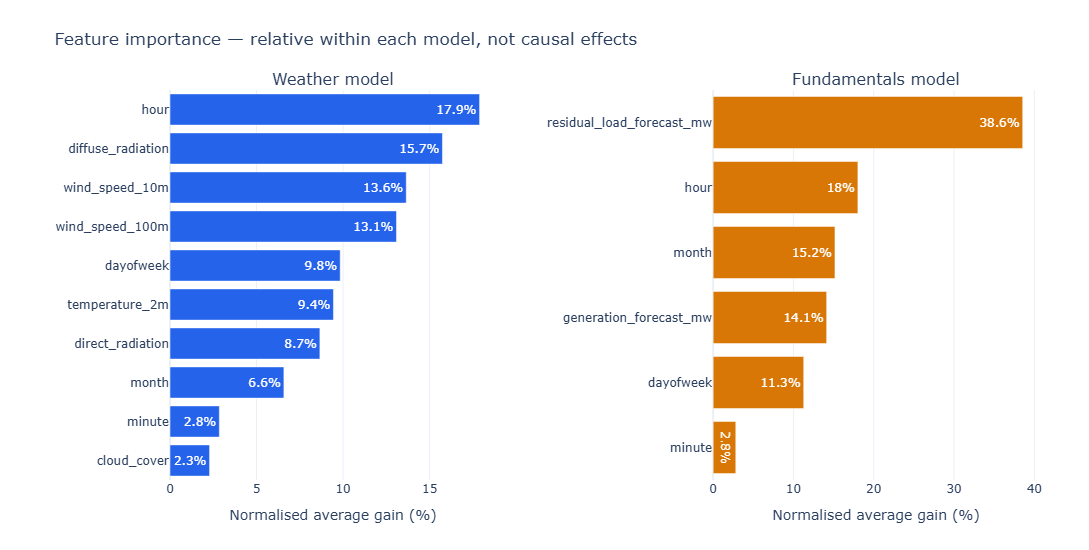

In [78]:
display(feature_importance_table(result).round(3))
feature_importance_figure(result).show()

## Relative MAE improvement
For **each evaluation subset separately**:

$$\text{fundamentals\_improvement\_pct}=100\times\frac{MAE_{weather}-MAE_{fundamentals}}{MAE_{weather}}.$$

- Weather MAE = 25, Fundamentals MAE = 20 → **+20%**: Fundamentals reduces absolute error by 20%.
- Weather MAE = 20, Fundamentals MAE = 25 → **−25%**: Fundamentals has 25% higher error.
- Equal nonzero MAE → 0%. If Weather MAE is zero, or the subset has no observations, the percentage is undefined (`NaN`).

The denominator is **Weather MAE**, not the benchmark and not the actual price. This is an error reduction, not a trading return or an accuracy score. Both models are evaluated on identical timestamps within each subset.

model,benchmark,fundamentals,weather,fundamentals_improvement_pct
subset,,,,
below_train_p90,41.18,37.29,38.99,4.38
high_fixed,113.43,105.19,108.77,3.29
high_train_quantile,85.86,79.04,83.62,5.49
overall,62.17,56.90,59.96,5.10


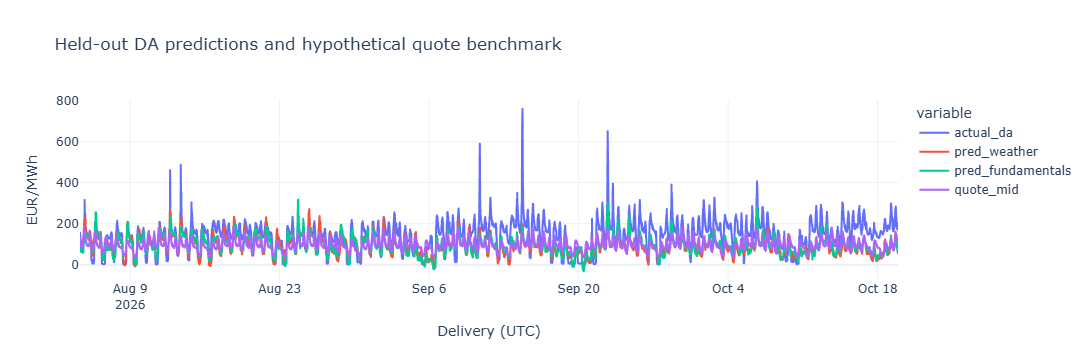

In [79]:
comparison = improvement_table(result['metrics'])
display(comparison.round(2))
prediction_figure(result['predictions']).show()

## Visualise the price groups

| Group | Definition |
|---|---|
| `below_train_p90` | Actual test price below the training quantile threshold (P90 by default) |
| `high_train_quantile` | Actual test price at or above the training quantile threshold |
| `high_fixed` | Actual test price at or above the configured fixed threshold (EUR 200/MWh by default) |

The first two groups partition the test set. `high_fixed` can overlap either group; do not add all three counts together. If you change `high_quantile`, `below_train_p90` retains its compatibility name but uses your new threshold, as shown in the plot title. Empty groups have `N=0` and unavailable metrics, not zero error.

The first plot compares MAE, RMSE and bias, with sample counts in the hover labels. The second shows actual and predicted prices within each group on the original time axis. These groups are defined after settlement for evaluation only; they do not influence trading decisions.

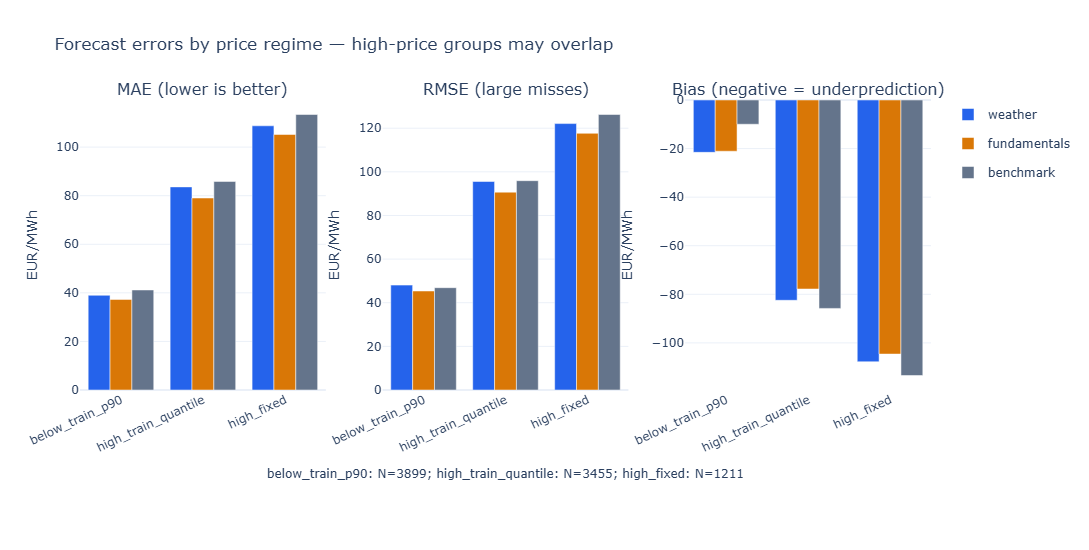

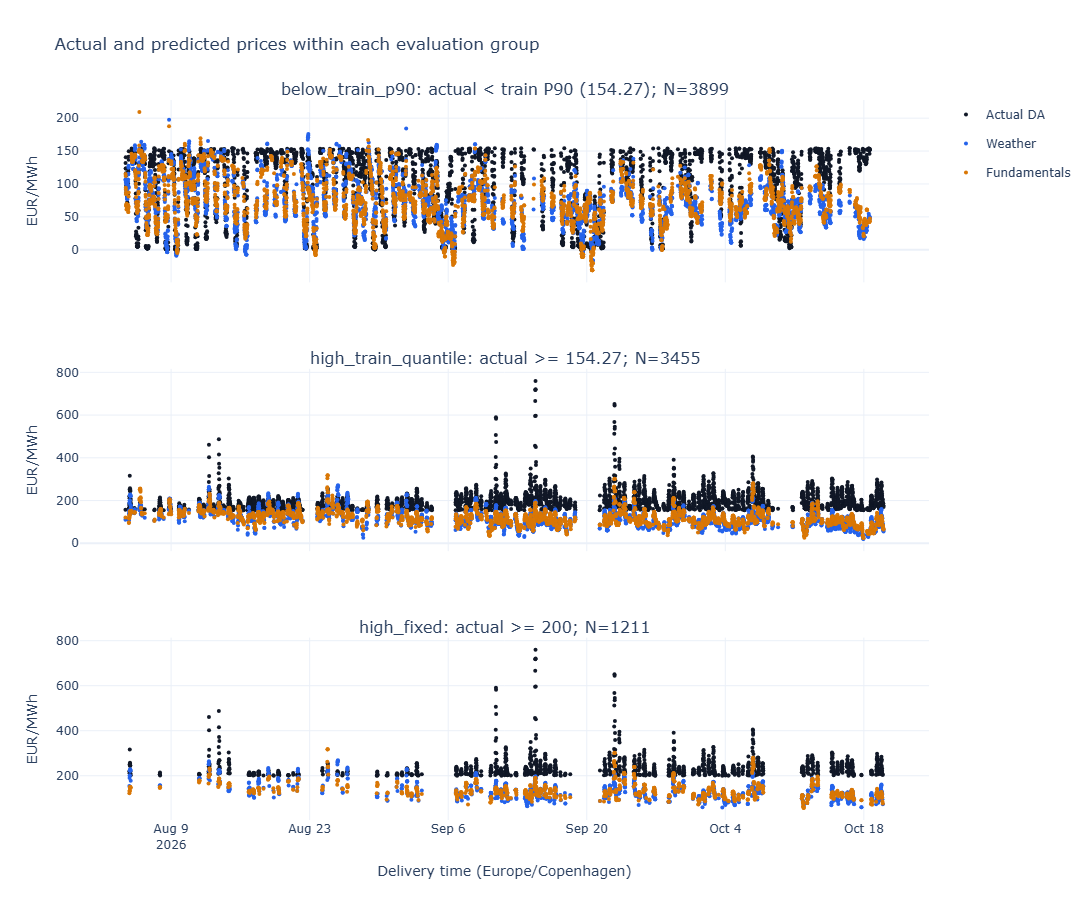

In [80]:
regime_metrics_figure(result).show()
regime_prices_figure(result).show()

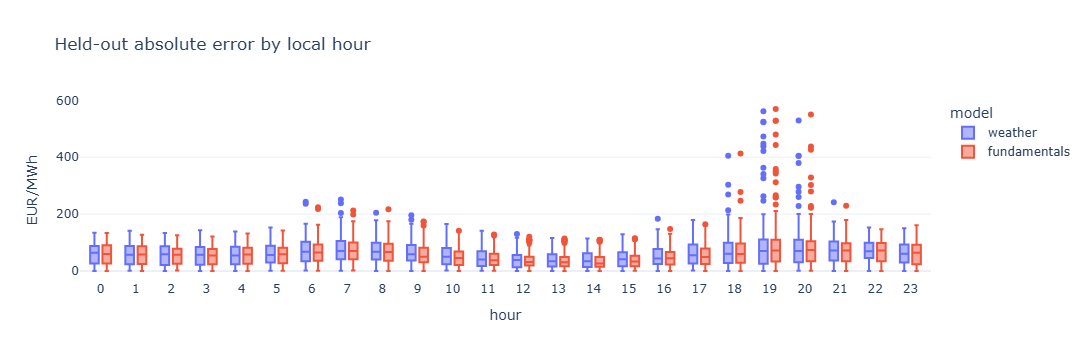

,actual_da,pred_weather,pred_fundamentals,quote_mid,decision_time_utc,duration_hours,eligible_for_contract,high_price
delivery_start_utc,,,,,,,,
2026-09-14 17:45:00+00:00,759.89,198.018738,190.259537,151.587955,2026-09-13 08:00:00+00:00,0.25,True,True
2026-09-14 18:00:00+00:00,721.10,191.968338,170.449280,151.234082,2026-09-13 08:00:00+00:00,0.25,True,True
2026-09-14 17:30:00+00:00,718.58,195.707962,189.972809,143.773182,2026-09-13 08:00:00+00:00,0.25,True,True
2026-09-14 17:15:00+00:00,717.52,192.692291,189.062271,142.522273,2026-09-13 08:00:00+00:00,0.25,True,True
2026-09-14 17:00:00+00:00,666.26,193.091202,186.551590,158.160000,2026-09-13 08:00:00+00:00,0.25,True,True
2026-09-22 17:15:00+00:00,651.40,203.921219,300.604919,163.916585,2026-09-21 08:00:00+00:00,0.25,True,True
2026-09-22 17:30:00+00:00,644.30,206.936890,301.368866,165.653415,2026-09-21 08:00:00+00:00,0.25,True,True
2026-09-14 18:15:00+00:00,597.03,191.569427,170.449280,145.429773,2026-09-13 08:00:00+00:00,0.25,True,True
2026-09-14 16:45:00+00:00,595.53,190.417664,182.076294,150.433636,2026-09-13 08:00:00+00:00,0.25,True,True


In [81]:
import plotly.express as px
predictions = result['predictions']
errors = []
for model in ['weather','fundamentals']:
    error = predictions[f'pred_{model}']-predictions.actual_da
    errors.append(pd.DataFrame({'hour':predictions.index.tz_convert(cfg.timezone).hour,
                                'model':model,'absolute_error':error.abs().to_numpy()}))
fig = px.box(pd.concat(errors), x='hour', y='absolute_error', color='model',
             title='Held-out absolute error by local hour', template='plotly_white')
fig.update_xaxes(tickmode='linear',dtick=1)
fig.update_yaxes(title='EUR/MWh')
fig.show()
display(predictions.nlargest(10,'actual_da'))

## Export to the contract project
The shared interface is `test_predictions.csv` plus `metadata.json`. It includes actual settlement prices, model forecasts, the frozen hypothetical quote, decision timestamps, interval duration, a high-price evaluation flag, and a trading-eligibility flag. The contract planner explicitly receives **only forecasts, quotes, duration and decision timestamps**; actual prices enter later in settlement.

To avoid training-completion look-ahead at the split boundary, assume all training labels are available only after the final training delivery interval. Decisions at or before that time are excluded from contract trading. This is conservative and separate from the unresolved forecast-vintage limitation.

The metadata includes a CSV checksum to detect mismatched files, configuration, features, split dates and source status. Saved model files and metrics support reproducibility. Synthetic and real outputs use different directories.


In [82]:
export_result(result, OUTPUT)
export_prediction_visuals(result, OUTPUT)
print(f'Exported prediction bundle to {OUTPUT.resolve()}')
print('Next: open hypothetical_contract.ipynb and set the matching DEMO flag.')

Exported prediction bundle to C:\Users\boons\quant\github-scripts\da_contract_project\prediction_output
Next: open hypothetical_contract.ipynb and set the matching DEMO flag.
